# Exploration du jeu de données 

Ce notebook charge les données, supprime les doublons, décrit les variables,
repère et traite les valeurs suspectes, puis sauvegarde un jeu de données nettoyé
dans `data/processed/`.

La variable `target` est étudiée ici uniquement pour information . Elle n'est jamais utilisée pour construire les clusters (voir le notebook 2)

## 1. Chargement et dimensions

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

CHEMIN_CSV = Path("../data/raw/Heart_disease_statlog.csv")

df = pd.read_csv(CHEMIN_CSV, encoding="utf-8")

print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])
df.head()

Nombre de lignes : 270
Nombre de colonnes : 14


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,70,1,3,130,322,0,2,109,0,2.4,1,3,1,1
1,67,0,2,115,564,0,2,160,0,1.6,1,0,3,0
2,57,1,1,124,261,0,0,141,0,0.3,0,0,3,1
3,64,1,3,128,263,0,0,105,1,0.2,1,1,3,0
4,74,0,1,120,269,0,2,121,1,0.2,0,1,1,0


In [2]:
df.dtypes

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object

In [3]:
# Listes des variables (nombres, mais de natures différentes)
VARIABLES_CONTINUES = ["age", "trestbps", "chol", "thalach", "oldpeak"]
VARIABLES_CATEGORIELLES = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

## 2. Doublons

In [4]:
# Repérage des doublons exacts (toutes les colonnes identiques)
nb_doublons = df.duplicated().sum()
print(f"Nombre de doublons exacts : {nb_doublons}")

# Suppression des doublons : on garde la première occurrence de chaque ligne
lignes_avant = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Lignes avant suppression : {lignes_avant}")
print(f"Lignes après suppression : {len(df)}")
print(f"Lignes supprimées : {lignes_avant - len(df)}")

Nombre de doublons exacts : 0
Lignes avant suppression : 270
Lignes après suppression : 270
Lignes supprimées : 0


## 3. Statistiques descriptives

In [5]:
# Statistiques descriptives des variables continues
df[VARIABLES_CONTINUES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,270.0,54.43,9.11,29.0,48.0,55.0,61.0,77.0
trestbps,270.0,131.34,17.86,94.0,120.0,130.0,140.0,200.0
chol,270.0,249.66,51.69,126.0,213.0,245.0,280.0,564.0
thalach,270.0,149.68,23.17,71.0,133.0,153.5,166.0,202.0
oldpeak,270.0,1.05,1.15,0.0,0.0,0.8,1.6,6.2


In [6]:
# Pour les variables catégorielles, on regarde les effectifs de chaque modalité
for variable in VARIABLES_CATEGORIELLES:
    print(df[variable].value_counts())


sex
1    183
0     87
Name: count, dtype: int64
cp
3    129
2     79
1     42
0     20
Name: count, dtype: int64
fbs
0    230
1     40
Name: count, dtype: int64
restecg
2    137
0    131
1      2
Name: count, dtype: int64
exang
0    181
1     89
Name: count, dtype: int64
slope
0    130
1    122
2     18
Name: count, dtype: int64
ca
0    160
1     58
2     33
3     19
Name: count, dtype: int64
thal
1    152
3    104
2     14
Name: count, dtype: int64


## 4. Distribution de la cible `target`

Nombre de 0 (pas de maladie) et de 1 (maladie), en effectif et en pourcentage.

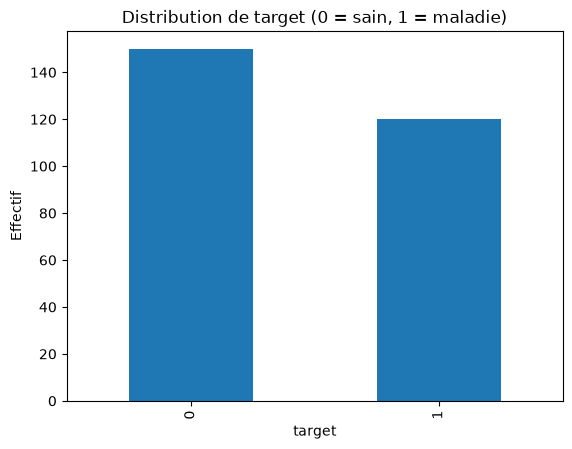

In [7]:
# Effectifs et pourcentages de la cible
effectifs = df["target"].value_counts()
pourcentages = (df["target"].value_counts() / len(df)) * 100

# Graphique en barres
effectifs.plot(kind="bar")
plt.title("Distribution de target (0 = sain, 1 = maladie)")
plt.xlabel("target")
plt.ylabel("Effectif")
plt.show()

Les modalités sont plus ou moins stables. 

## 5. Distribution des variables

Histogrammes pour les variables continues, puis diagrammes en barres pour les catégorielles.

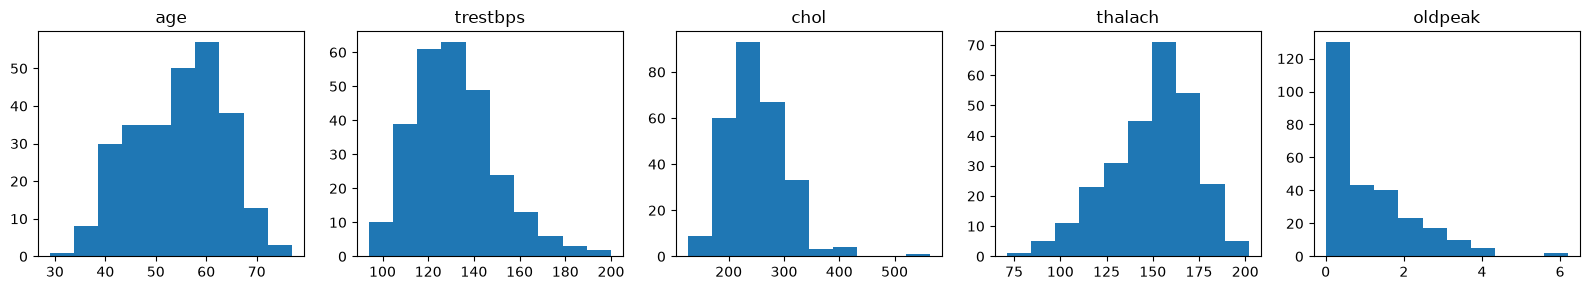

In [8]:
# Histogrammes des variables continues
fig, axes = plt.subplots(1, len(VARIABLES_CONTINUES), figsize=(16, 3))
for ax, variable in zip(axes, VARIABLES_CONTINUES):
    ax.hist(df[variable])
    ax.set_title(variable)
plt.tight_layout()
plt.show()

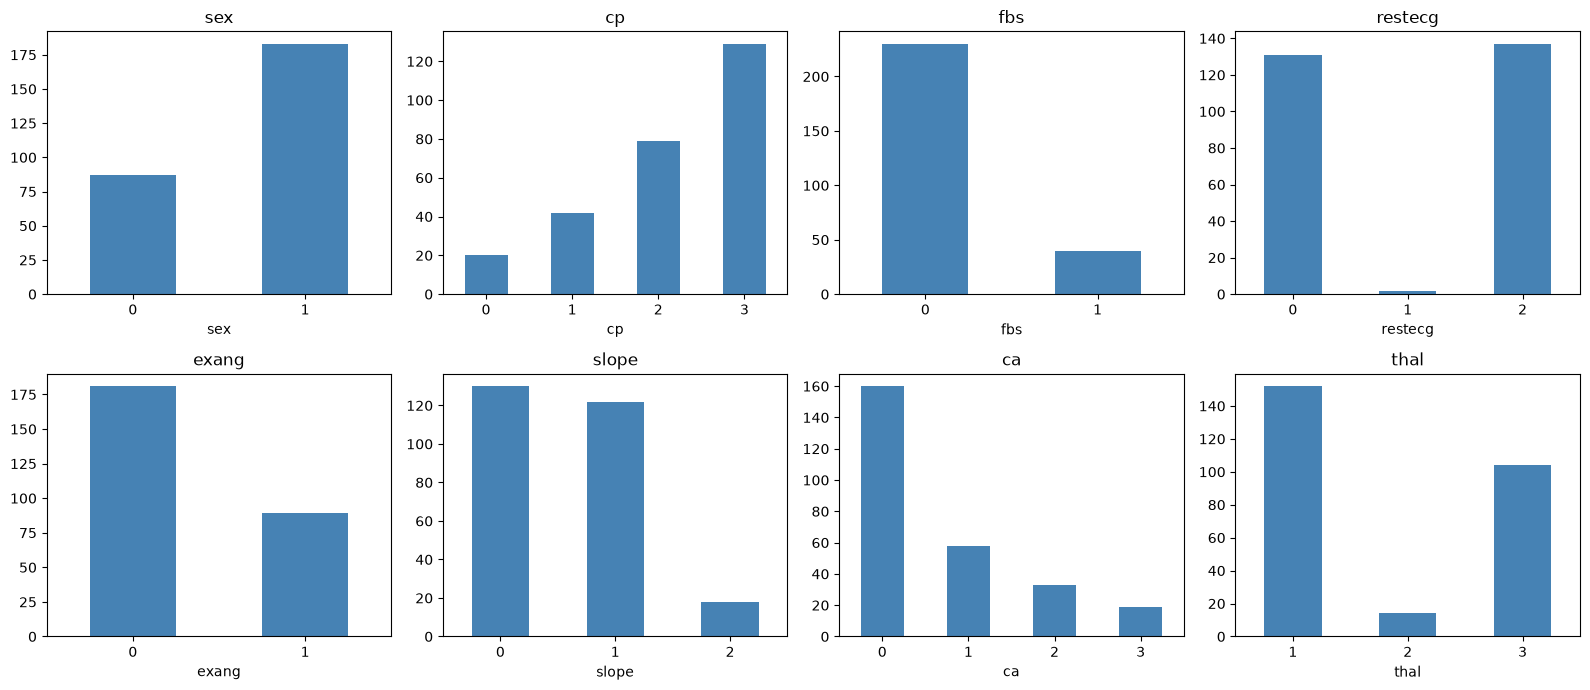

In [9]:
# Diagrammes en barres des variables catégorielles
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, variable in zip(axes.flatten(), VARIABLES_CATEGORIELLES):
    df[variable].value_counts().sort_index().plot(kind="bar", ax=ax, color="steelblue", rot=0)
    ax.set_title(variable)
plt.tight_layout()
plt.show()

## 6. Valeurs suspectes

D'après la documentation UCI Heart Disease :
- `thal` ne prend que les valeurs 1, 2 ou 3 : la valeur **0** est donc invalide ;
- `ca` (nombre de vaisseaux colorés) va de 0 à 3 : la valeur **4** est donc invalide.

In [10]:
# Lignes contenant des valeurs hors documentation
suspects_thal = df[df["thal"] == 0]
suspects_ca = df[df["ca"] == 4]

print("Valeurs de thal :", sorted(df["thal"].unique()))
print("Valeurs de ca   :", sorted(df["ca"].unique()))

print(f"thal suspect : {len(suspects_thal)}")
print(f"ca susupec : {len(suspects_ca)}")



Valeurs de thal : [np.int64(1), np.int64(2), np.int64(3)]
Valeurs de ca   : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
thal suspect : 0
ca susupec : 0


### Traitement retenu

Dans ce jeu de données, aucune valeur suspecte n'est détectée : `thal` ne prend
que 1, 2 ou 3 et `ca` que 0 à 3. Aucune ligne n'est donc supprimée.
Le filtre ci-dessous est conservé : il ne supprimerait rien ici, mais protège le
pipeline si le fichier change. Si une valeur suspecte apparaissait, on la
supprimerait.

In [11]:
# Suppression des lignes contenant une valeur suspecte
lignes_avant = len(df)
df_propre = df[(df["thal"] != 0) & (df["ca"] != 4)].reset_index(drop=True)

print(f"Lignes avant : {lignes_avant}")
print(f"Lignes après : {len(df_propre)}")
print(f"Lignes supprimées : {lignes_avant - len(df_propre)}")

Lignes avant : 270
Lignes après : 270
Lignes supprimées : 0


## 7. Sauvegarde du jeu de données nettoyé

In [12]:
# Sauvegarde dans data/processed/ (le fichier brut reste intact)
dossier_processed = Path("../data/processed")
dossier_processed.mkdir(parents=True, exist_ok=True)
chemin_sortie = dossier_processed / "heart_propre.csv"
df_propre.to_csv(chemin_sortie, index=False)

print("Fichier sauvegardé :", chemin_sortie)
print("Dimensions :", df_propre.shape)

Fichier sauvegardé : ..\data\processed\heart_propre.csv
Dimensions : (270, 14)
